# Burstiness Analysis - keyword topics

## Import libraries and data

In [1]:
import pickle
import numpy as np
import pandas as pd
from collections import Counter
from datetime import datetime
from dateutil.relativedelta import relativedelta
import matplotlib.pyplot as plt
from itertools import chain

In [2]:
# Read in data - replace with final deidentified pkl files

with open('../data/aus/clean/aus_deidentified_min_fields.pkl', 'rb') as f:
    aus = pickle.load(f, encoding="utf-8")

with open('../data/canada/clean/can_deidentified_min_fields.pkl', 'rb') as f:
    can = pickle.load(f, encoding="utf-8")
    
with open('../data/uk/clean/uk_deidentified_min_fields.pkl', 'rb') as f:
    uk = pickle.load(f, encoding="utf-8")

## Identifying which gaps in petitioning are likely due to elections/site shutdowns

In [4]:
def plot_date_and_gaps(dates, gaps):
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.eventplot(dates, orientation='horizontal', linelengths=0.5, colors='b')
    ax.eventplot(gaps, orientation='horizontal', linelengths=0.5, colors='r')
    
    ax.set_xlabel('Date', fontsize = 11, labelpad = 10)
    ax.yaxis.set_visible(False)
    plt.show()
    
    return fig, ax

In [5]:
## Canada shutdown dates: 2019-09-11, 2021-08-15, 2025-03-23

# aus_elections = ['2025-05-03', '2022-05-21', '2019-05-18', '2016-07-02']

# UK elections: 2024-07-04, 2019-12-12, 2017-06-08, 2015-05-07, 2010-05-06

can_shutdown = [datetime(2019, 9, 11, 0, 0, 0), datetime(2021, 8, 15, 0, 0, 0), datetime(2025, 3, 23, 0, 0, 0)]

can_elections = [datetime(2025, 4, 28, 0, 0, 0), 
                 datetime(2021, 9, 20, 0, 0, 0), 
                 datetime(2019, 10, 21, 0, 0, 0)] # datetime(2015, 10, 19, 0, 0, 0)

aus_elections =[datetime(2025, 5, 3, 0, 0, 0), 
 datetime(2022, 5, 21, 0, 0, 0), 
 datetime(2019, 5, 18, 0, 0, 0)] # datetime(2016, 7, 2, 0, 0, 0)

uk_elections = [datetime(2024, 7, 4, 0, 0, 0),
datetime(2019, 12, 12, 0, 0, 0),
datetime(2017, 6, 8, 0, 0, 0),
datetime(2015, 5, 7, 0, 0, 0)] #datetime(2010, 5, 6, 0, 0, 0)

aus_dates = [aus[k]['date'] for k in aus.keys()]
can_dates = [can[k]['date'] for k in can.keys()]
uk_dates = [uk[k]['date'] for k in uk.keys()]

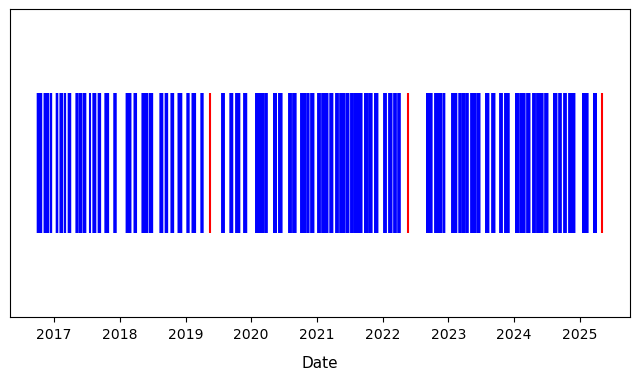

(<Figure size 800x400 with 1 Axes>, <Axes: xlabel='Date'>)

In [6]:
plot_date_and_gaps(aus_dates, aus_elections)

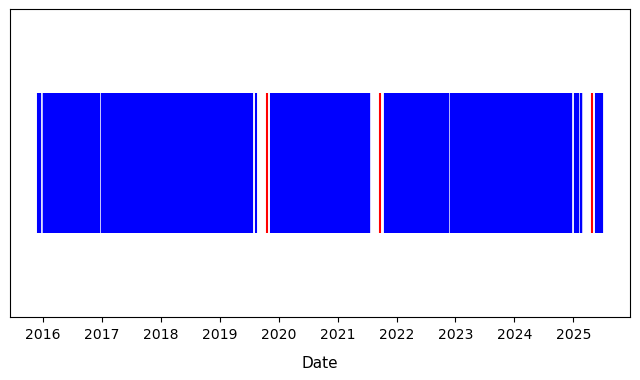

(<Figure size 800x400 with 1 Axes>, <Axes: xlabel='Date'>)

In [7]:
plot_date_and_gaps(can_dates, can_elections)

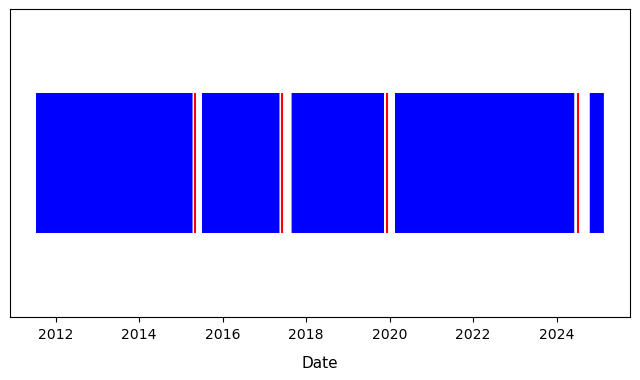

(<Figure size 800x400 with 1 Axes>, <Axes: xlabel='Date'>)

In [8]:
plot_date_and_gaps(uk_dates, uk_elections)

## Running burstiness process and saving results

In [9]:
from burstiness_functions_v5 import *

In [10]:
date_field = 'date'
keyword_field = 'burstiness_keywords'
terms = ['climate', 'health', 'law', 'migration']

In [11]:
aus_term_BM_df = burstiness_df_create(aus, terms, date_field, keyword_field, 'aus')

climate
170
health
765
law
736
migration
199


In [12]:
aus_term_BM_df
aus_term_BM_df.to_csv('./results/aus_keywords_BM_v2.csv', index=False)

In [13]:
can_term_BM_df = burstiness_df_create(can, terms, date_field, keyword_field, 'can')

climate
114
health
508
law
410
migration
101


In [14]:
can_term_BM_df
can_term_BM_df.to_csv('./results/can_keywords_BM_v2.csv', index=False)

In [15]:
uk_term_BM_df = burstiness_df_create(uk, terms, date_field, keyword_field, 'uk')

climate
758
health
5322
law
6759
migration
621


In [16]:
uk_term_BM_df
uk_term_BM_df.to_csv('./results/uk_keywords_BM_v2.csv', index=False)